In [1]:
import spam.DIC
import spam.helpers
import tifffile
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage
from pathlib import Path

In [2]:
# helper functions
def red_green_overlay(red_volume: np.ndarray, green_volume: np.ndarray,
                       vmin: float = 0, vmax: float = None) -> np.ndarray:
    """
    Builds an RGB image with `red_volume` in the red channel and
    `green_volume` in the green channel, for visually checking spatial
    overlap (well-aligned structures appear yellow).

    Parameters
    ----------
    red_volume : ndarray
        2D image for the red channel (e.g. a max-z projection of
        `proj_1_pad`).

    green_volume : ndarray
        2D image for the green channel, same shape as `red_volume`.

    vmin : float
        Intensity mapped to zero channel brightness, for both
        channels.

    vmax : float or None
        Intensity mapped to full channel brightness. If None (default),
        each channel is normalized independently, using its own 99.9th
        percentile — needed when the two inputs are on very different
        scales (e.g. raw counts vs. `log1p`-compressed, or two
        different modalities entirely). Pass an explicit value to use
        the same scale for both channels instead.

    Returns
    -------
    ndarray
        RGB image of shape `(*red_volume.shape, 3)`, float in [0, 1].
    """
    red_vmax = np.percentile(red_volume, 99.9) if vmax is None else vmax
    green_vmax = np.percentile(green_volume, 99.9) if vmax is None else vmax

    rgb = np.zeros((*red_volume.shape, 3))
    rgb[..., 0] = np.clip((red_volume - vmin) / (red_vmax - vmin), 0, 1)
    rgb[..., 1] = np.clip((green_volume - vmin) / (green_vmax - vmin), 0, 1)
    return rgb


def per_label_overlay(label: int, PhiField: np.ndarray, margin: int = 20,
                       mask_dilate: int = 0, ax_proj: int = 0) -> np.ndarray:
    """
    Crops REFERENCE and TARGET around `label`, warps REFERENCE by
    `PhiField[label]`, and returns a max-projected red/green overlay
    with everything except `label`'s own (optionally dilated) footprint
    masked out on both sides - so only this segment's alignment is
    visible, without surrounding tissue or other labels cluttering the
    view.

    The mask is applied to REFERENCE *before* warping (so it gets
    carried along by the same Phi as the image content), and separately
    warped by the same Phi to mask TARGET at wherever the label ends up
    landing - not at its original (pre-alignment) position.

    Parameters
    ----------
    label : int
        Label to visualize.

    PhiField : ndarray
        Per-label Phi array (e.g. `PhiField_ddic`, `PhiField_ps`, or a
        manually-corrected `PhiField_manual`).

    margin : int
        Margin (voxels) added around `label`'s bounding box for the
        crop.

    mask_dilate : int
        Number of voxels to dilate `label`'s mask by before applying
        it. Many labels are thin/sparse relative to their own bounding
        box (can be <1% of it) and may barely show up undilated.
        Default 0 (no dilation).

    ax_proj : int
        Axis to max-project along for display.

    Returns
    -------
    ndarray
        RGB overlay image, REFERENCE (warped, masked) in red, TARGET
        (masked) in green.
    """
    bbox = boundingBoxes[label]
    zmin, zmax = max(bbox[0] - margin, 0), min(bbox[1] + margin + 1, ref.shape[0])
    ymin, ymax = max(bbox[2] - margin, 0), min(bbox[3] + margin + 1, ref.shape[1])
    xmin, xmax = max(bbox[4] - margin, 0), min(bbox[5] + margin + 1, ref.shape[2])
    crop_slice = (slice(zmin, zmax), slice(ymin, ymax), slice(xmin, xmax))

    ref_crop = ref[crop_slice]
    tar_crop = tar[crop_slice]
    PhiCentre = centresOfMass[label] - np.array([zmin, ymin, xmin])

    mask = lab1[crop_slice] == label
    if mask_dilate > 0:
        mask = scipy.ndimage.binary_dilation(mask, iterations=mask_dilate)

    ref_crop_deformed = spam.DIC.applyPhi(np.where(mask, ref_crop, 0), Phi=PhiField[label], PhiCentre=PhiCentre)
    # NOTE: applyPhi only actually implements interpolationOrder=1 (its own docstring says so) -
    # passing interpolationOrder=0 is unvalidated and segfaults the C interpolator on real
    # (non-identity) Phi. Trilinear-interpolating the 0/1 mask and thresholding works fine.
    mask_deformed = spam.DIC.applyPhi(mask.astype('float32'), Phi=PhiField[label], PhiCentre=PhiCentre) > 0.5
    tar_crop_masked = np.where(mask_deformed, tar_crop, 0)

    return red_green_overlay(np.max(ref_crop_deformed, axis=ax_proj), np.max(tar_crop_masked, axis=ax_proj), vmin=100)

In [3]:
overwrite = True

In [4]:
# select data
spam_folder = Path('/mnt/labserver/data/MA/SCAPE/spam')
tif_folder = spam_folder / 'tif_files'
tar_name = 'ref_R'
ref = tifffile.imread(tif_folder / f'{tar_name}_REFERENCE_prealigned.tif')
tar = tifffile.imread(tif_folder / f'{tar_name}_TARGET_prealigned.tif')

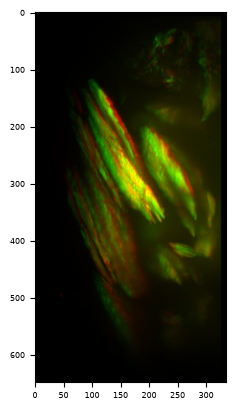

In [ ]:
# visualize
ax_proj = 0
ref_slice = np.max(ref, axis=ax_proj)
tar_slice = np.max(tar, axis=ax_proj)

# overlay to compare
overlay = red_green_overlay(ref_slice, tar_slice, vmin=100)
plt.imshow(overlay)


In [19]:
# load labels (always on the reference side) and their bounding boxes / centres of mass
import spam.label

lab1 = tifffile.imread(tif_folder / f'{tar_name}_LABELS_prealigned.tif')
boundingBoxes = spam.label.boundingBoxes(lab1)
centresOfMass = spam.label.centresOfMass(lab1, boundingBoxes=boundingBoxes)
print('lab1:', lab1.shape, lab1.dtype, ' number of labels:', lab1.max())

# also load muscles
mus1 = tifffile.imread(tif_folder / f'{tar_name}_MUSCLES_prealigned.tif')

lab1: (208, 648, 335) uint32  number of labels: 3


In [7]:
# RIGID REGISTRATION as a starting point

# try loading if it exists
registration_file_name = f'{tar_name}-registration.tsv'
try:
    if overwrite:
        print('overwriting!')
        raise Exception
    phi = spam.helpers.readCorrelationTSV(spam_folder / registration_file_name)['PhiField'][0]
    print('LOADED PRE-EXISTANT REGISTRATION')

except:
    # run rigid registration and save
    print('Running rigid pre-registration...')
    reg = spam.DIC.registerMultiscale(
        ref, tar,
        binStart=4, binStop=1,
        PhiInit=None,
        PhiRigid=True,
        verbose=True,
    )
    print('returnStatus:', reg['returnStatus'], '(2 = converged)')
    print('error:', reg['error'])

    regCentre = (np.array(ref.shape) - 1) / 2.0
    spam.helpers.writeRegistrationTSV(spam_folder / registration_file_name, regCentre, reg)
    phi = reg['Phi']

overwriting!
Running rigid pre-registration...

	spam.DIC.registerMultiscale(): working on binning:  4


/home/azcorra/git/Devel/Pupa_muscle_imaging/SPAM_registration/.venv/lib/python3.11/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

It#:001 |δΦ|=0.94004 error=   5.77 t=[ -0.488  -0.344  -0.726]px r=[  0.261   0.385  -0.135]° stretch=[1.000 1.000 
1.000]


Start correlation with Error = 9.86


It#:002 |δΦ|=0.50707 error=   5.10 t=[ -0.729  -0.528  -1.131]px r=[  0.190   1.327  -0.095]° stretch=[1.000 1.000 
1.000]

...

It#:024 |δΦ|=0.00019 error=   6.50 t=[ -3.663  -2.859  -6.036]px r=[ -0.204   2.114   0.010]° stretch=[1.000 1.000 
1.000]

It#:025 |δΦ|=0.00015 error=   6.50 t=[ -3.663  -2.859  -6.036]px r=[ -0.204   2.114   0.010]° stretch=[1.000 1.000 
1.000]

It#:026 |δΦ|=0.00011 error=   6.50 t=[ -3.663  -2.859  -6.036]px r=[ -0.204   2.114   0.010]° stretch=[1.000 1.000 
1.000]

It#:027 |δΦ|=0.00009 error=   6.50 t=[ -3.663  -2.859  -6.036]px r=[ -0.204   2.114   0.010]° stretch=[1.000 1.000 
1.000]


	 → Converged
returnStatus: 2 (2 = converged)
error: 6.49684


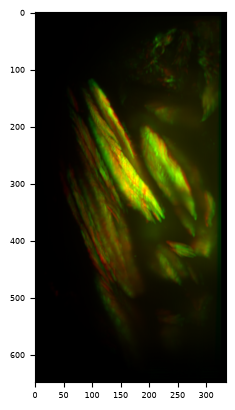

In [8]:
# warp REFERENCE by the found Phi so it's in TARGET's frame
ref_deformed = spam.DIC.applyPhi(ref, Phi=phi)

ax_proj = 0
ref_slice = np.max(ref_deformed, axis=ax_proj)
tar_slice = np.max(tar, axis=ax_proj)

# overlay to compare
overlay = red_green_overlay(ref_slice, tar_slice, vmin=100)
plt.imshow(overlay)


In [9]:
# PER-LABEL LOCAL REFINEMENT (spam-pixelSearch -lab1 equivalent)

pixelsearch_file_name = f'{tar_name}-pixelSearch.tsv'
try:
    if overwrite:
        print('overwriting!')
        raise Exception
    PhiField_ps = spam.helpers.readCorrelationTSV(spam_folder / pixelsearch_file_name)['PhiField']

except:
    print('Running pixel search...')
    # broadcast the single whole-image Phi onto every label's centre of mass
    regCentre = (np.array(ref.shape) - 1) / 2.0
    PhiField_seed = spam.DIC.applyRegistrationToPoints(phi, regCentre, centresOfMass, applyF='all')

    search_range = np.array([-10, 10, -10, 10, -10, 10])  # Zlo Zhi Ylo Yhi Xlo Xhi, in px

    ps = spam.DIC.pixelSearchDiscrete(
        lab1, ref, tar, search_range,
        PhiField=PhiField_seed,
        boundingBoxes=boundingBoxes,
        centresOfMass=centresOfMass,
        labelDilate=0,
        applyF='no',
    )
    PhiField_ps = ps['PhiField']
    print('returnStatus per label:', ps['returnStatus'])

    # keep row 0 (background placeholder, never searched) so array index == label ID is preserved
    # when this file is read back - just needs to be the same length as everything else
    numberOfLabels = lab1.max()
    outMatrix = np.array([
        np.arange(0, numberOfLabels + 1),
        centresOfMass[:, 0], centresOfMass[:, 1], centresOfMass[:, 2],
        PhiField_ps[:, 0, 0], PhiField_ps[:, 0, 1], PhiField_ps[:, 0, 2], PhiField_ps[:, 0, 3],
        PhiField_ps[:, 1, 0], PhiField_ps[:, 1, 1], PhiField_ps[:, 1, 2], PhiField_ps[:, 1, 3],
        PhiField_ps[:, 2, 0], PhiField_ps[:, 2, 1], PhiField_ps[:, 2, 2], PhiField_ps[:, 2, 3],
        ps['pixelSearchCC'], ps['returnStatus'], ps['error'], np.ones(numberOfLabels + 1), ps['iterations'],
    ]).T
    np.savetxt(
        spam_folder / pixelsearch_file_name, outMatrix, fmt='%.7f', delimiter='\t', newline='\n', comments='',
        header='Label\tZpos\tYpos\tXpos\tFzz\tFzy\tFzx\tZdisp\tFyz\tFyy\tFyx\tYdisp\tFxz\tFxy\tFxx\tXdisp\tpixelSearchCC\treturnStatus\terror\tdeltaPhiNorm\titerations',
    )

overwriting!
Running pixel search...

	Starting Pixel Search Discrete (with 12 processes)


returnStatus per label: [0 1 1 1]


	spam.tsvio.readCorrelationTSV(): Number of labels: 4


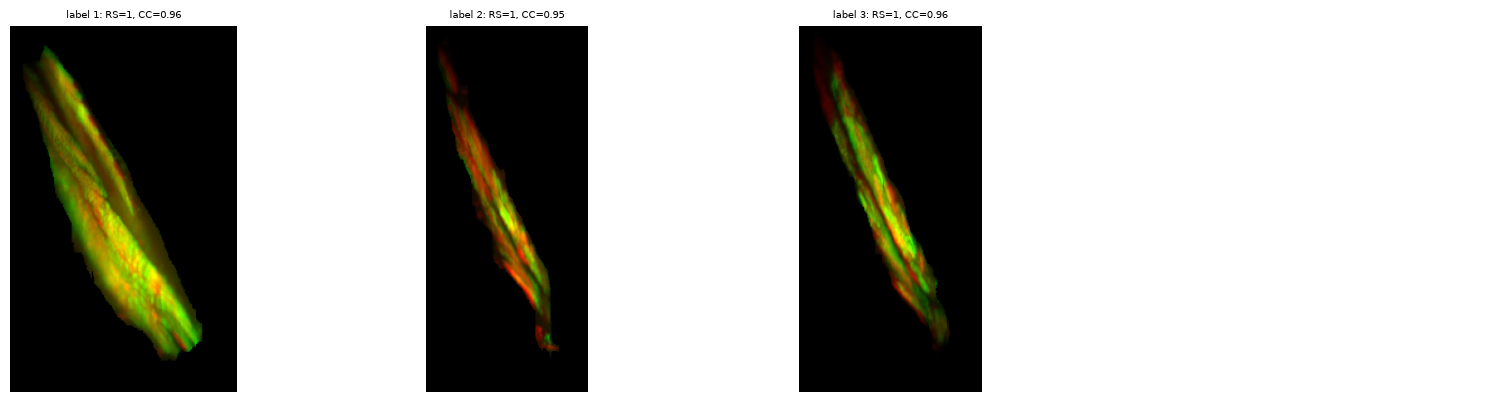

In [10]:
# CHECK PER-LABEL PIXEL-SEARCH RESULT (the starting guess ddic will refine from)

# read fresh from the TSV so this works whether the pixel search cell above just ran or loaded from cache
ps_results = spam.helpers.readCorrelationTSV(spam_folder / pixelsearch_file_name, readError=True, readPixelSearchCC=True)
PhiField_ps_check = ps_results['PhiField']
returnStatus_ps = ps_results['returnStatus']
pixelSearchCC_ps = ps_results['pixelSearchCC']

numberOfLabels = lab1.max()

n_cols = 4
n_rows = int(np.ceil(numberOfLabels / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
axes = np.array(axes).flatten()

for label in range(1, numberOfLabels + 1):
    overlay = per_label_overlay(label, PhiField_ps_check)

    ax = axes[label - 1]
    ax.imshow(overlay)
    ax.set_title(f'label {label}: RS={returnStatus_ps[label]:.0f}, CC={pixelSearchCC_ps[label]:.2f}')
    ax.axis('off')

for ax in axes[numberOfLabels:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [11]:
# PER-LABEL DEFORMABLE CORRELATION (spam-ddic equivalent)

ddic_file_name = f'{tar_name}-ddic.tsv'
try:
    if overwrite:
        print('overwriting!')
        raise Exception
    ddic_tsv = spam.helpers.readCorrelationTSV(spam_folder / ddic_file_name)
    PhiField_ddic = ddic_tsv['PhiField']
    returnStatus_ddic = ddic_tsv['returnStatus']

except:
    print('Running ddic...')
    numberOfLabels = lab1.max()
    PhiField_ddic, returnStatus_ddic, error_ddic, iterations_ddic, deltaPhiNorm_ddic, labelDilateList_ddic, PSCC_ddic = spam.DIC.ddic(
        ref, tar, lab1,
        labelsToCorrelate=np.arange(1, numberOfLabels + 1),  # spam.DIC.ddic()'s own default
                                                              # (labelsToCorrelate=None -> arange(1, lab1.max()))
                                                              # silently drops the highest-numbered label - the
                                                              # CLI script always passes this explicitly, so it
                                                              # never hits the bug; we have to too
        PhiField=PhiField_ps,
        boundingBoxes=boundingBoxes,
        centresOfMass=centresOfMass,
        labelDilate=0,
        correlateRigid=False,
    )
    print('returnStatus per label:', returnStatus_ddic)
    print('error per label:', error_ddic)

    # keep row 0 (background placeholder, never searched) so array index == label ID is preserved
    # when this file is read back - just needs to be the same length as everything else
    outMatrix = np.array([
        np.arange(0, numberOfLabels + 1),
        centresOfMass[:, 0], centresOfMass[:, 1], centresOfMass[:, 2],
        PhiField_ddic[:, 0, 3], PhiField_ddic[:, 1, 3], PhiField_ddic[:, 2, 3],
        PhiField_ddic[:, 0, 0], PhiField_ddic[:, 0, 1], PhiField_ddic[:, 0, 2],
        PhiField_ddic[:, 1, 0], PhiField_ddic[:, 1, 1], PhiField_ddic[:, 1, 2],
        PhiField_ddic[:, 2, 0], PhiField_ddic[:, 2, 1], PhiField_ddic[:, 2, 2],
        PSCC_ddic, error_ddic, iterations_ddic, returnStatus_ddic, deltaPhiNorm_ddic, labelDilateList_ddic,
    ]).T
    np.savetxt(
        spam_folder / ddic_file_name, outMatrix, fmt='%.7f', delimiter='\t', newline='\n', comments='',
        header='Label\tZpos\tYpos\tXpos\tZdisp\tYdisp\tXdisp\tFzz\tFzy\tFzx\tFyz\tFyy\tFyx\tFxz\tFxy\tFxx\tPSCC\terror\titerations\treturnStatus\tdeltaPhiNorm\tLabelDilate',
    )

overwriting!
Running ddic...

	Starting discrete dic for 3 labels (with 12 processes)


                 Discrete DIC summary                  
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃              Status ┃ Number of labels ┃ Percentage ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│     Converged: RS=2 │                0 │      0.00% │
│ Not converged: RS=1 │                3 │    100.00% │
│      Diverged: RS<0 │                0 │      0.00% │
└─────────────────────┴──────────────────┴────────────┘

returnStatus per label: [0 1 1 1]
error per label: [ 0.    28.802 20.783 18.746]


	spam.tsvio.readCorrelationTSV(): Number of labels: 4


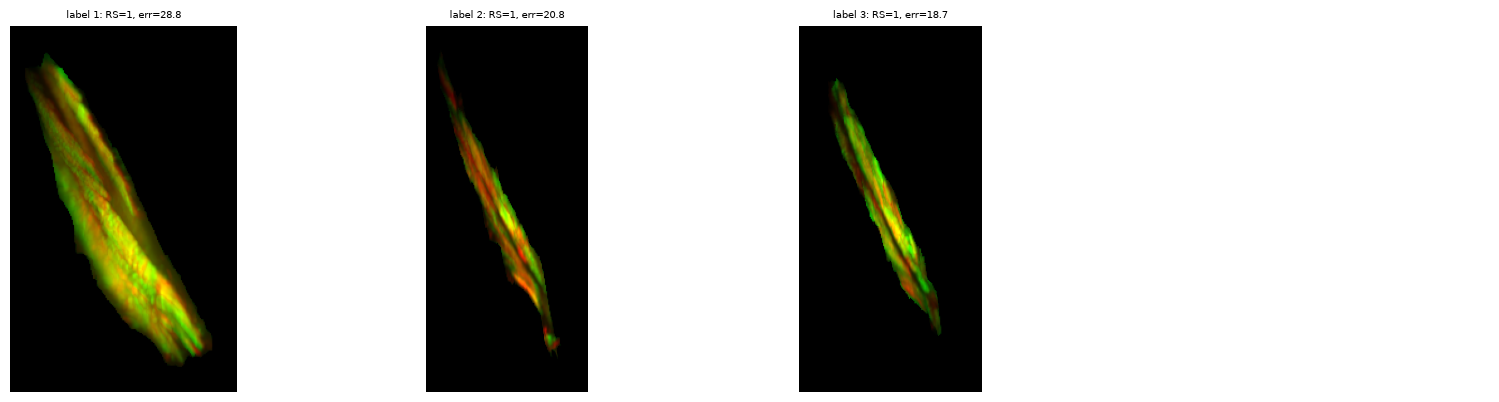

In [12]:
# CHECK PER-LABEL ALIGNMENT: warp each label's REFERENCE crop by its own found Phi, overlay against TARGET

# read fresh from the TSV so this works whether the ddic cell above just ran or loaded from cache
ddic_results = spam.helpers.readCorrelationTSV(spam_folder / ddic_file_name, readError=True)
PhiField_ddic = ddic_results['PhiField']
returnStatus_ddic = ddic_results['returnStatus']
error_ddic = ddic_results['error']

numberOfLabels = lab1.max()

n_cols = 4
n_rows = int(np.ceil(numberOfLabels / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
axes = np.array(axes).flatten()

for label in range(1, numberOfLabels + 1):
    overlay = per_label_overlay(label, PhiField_ddic)

    ax = axes[label - 1]
    ax.imshow(overlay)
    ax.set_title(f'label {label}: RS={returnStatus_ddic[label]:.0f}, err={error_ddic[label]:.1f}')
    ax.axis('off')

for ax in axes[numberOfLabels:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# REASSEMBLE THE WHOLE REGISTERED IMAGE: each segment warped by its own found Phi, stitched together

def assemble_registered_image(PhiField: np.ndarray, dilate: int = 0) -> tuple:
    """
    Builds full-size intensity and label volumes where each label's
    REFERENCE content has been individually warped by its own
    `PhiField[label]`, so every segment lands in its own registered
    position/shape - as opposed to a single, uniform, whole-image Phi.

    For each label, the *whole* REFERENCE volume is warped by that
    label's own Phi (anchored at its centre of mass), then masked down
    to just that label's own footprint before being pasted into the
    shared output canvas - the intensity canvas (REFERENCE greyvalues),
    the `lab1` label canvas (that label's own ID), and the `mus1`
    ("muscle") label canvas. `mus1` is not used for the registration
    itself (only `lab1` is) - it is just carried along with the Phi of
    the `lab1` segment each muscle sits in. Each `mus1` muscle is warped
    as its own binary mask (intersected with this segment's mask, in
    case a muscle straddles two segments - the other segment's
    iteration picks up its own portion) using this same segment's Phi,
    one muscle ID at a time - trilinear-interpolating a multi-ID label
    map directly would blend adjacent muscle IDs into meaningless
    fractional values at their boundaries, so each ID needs its own 0/1
    mask, same as `lab1`'s.

    Warping the whole volume (rather than a small crop around the
    label) avoids any risk of a large per-label displacement clipping
    against a small crop's edges. Since the original labels are
    disjoint, their independently-warped footprints shouldn't overlap
    either - if any do, it's printed as a warning, including the
    overlap as a fraction of this label's own (warped) size, to help
    judge how serious it is (and whichever label is processed later
    wins there, same as any other overlap).

    Parameters
    ----------
    PhiField : ndarray
        Per-label Phi array (e.g. `PhiField_ddic`, or a mix of
        automatic and manually-corrected (`spam-ereg`) results, see
        `import_ereg_result`). Indexed by `lab1` label IDs.

    dilate : int
        Number of voxels to dilate each `lab1` label's mask by before
        pasting, to slightly grow segments and reduce visible seams/
        gaps between neighbouring segments. Default 0 (exact masks).
        Not applied to `mus1` muscle masks.

    Returns
    -------
    tuple of ndarray
        `(assembled, assembled_labels, assembled_muscles)`:
        - `assembled`: full-size intensity volume, same shape/dtype as
          `ref`, assembled from all labels' individually-warped content.
        - `assembled_labels`: full-size label volume, same shape/dtype
          as `lab1`, with each label's own ID painted into its warped
          footprint - the labelled counterpart of `assembled`.
        - `assembled_muscles`: full-size label volume, same shape/dtype
          as `mus1`, with each muscle's own ID painted into its warped
          footprint, each warped by its containing `lab1` segment's Phi.
    """
    assembled = np.zeros_like(ref)
    assembled_labels = np.zeros_like(lab1)
    assembled_muscles = np.zeros_like(mus1)
    owner = np.zeros(ref.shape, dtype=int)  # 0 = unclaimed, else = label that has already claimed this voxel

    for label in range(1, lab1.max() + 1):
        segment_mask = lab1 == label
        mask = scipy.ndimage.binary_dilation(segment_mask, iterations=dilate) if dilate > 0 else segment_mask

        ref_warped = spam.DIC.applyPhi(np.where(mask, ref, 0), Phi=PhiField[label], PhiCentre=centresOfMass[label])
        mask_warped = spam.DIC.applyPhi(mask.astype('float32'), Phi=PhiField[label],
                                         PhiCentre=centresOfMass[label]) > 0.5

        total = int(mask_warped.sum())
        overlap = mask_warped & (owner != 0)
        if overlap.any():
            overlapping_labels = np.unique(owner[overlap]).tolist()
            n_overlap = int(overlap.sum())
            print(f'WARNING: label {label} overlaps with label(s) {overlapping_labels} in '
                  f'{n_overlap}/{total} voxels ({100 * n_overlap / total:.1f}%) after warping - '
                  f'labels should be disjoint')

        assembled[mask_warped] = ref_warped[mask_warped]
        assembled_labels[mask_warped] = label
        owner[mask_warped] = label

        # carry the muscles inside this segment along with this segment's Phi (undilated segment mask)
        muscle_ids = np.unique(mus1[segment_mask])
        for muscle in muscle_ids[muscle_ids != 0]:
            muscle_mask = (mus1 == muscle) & segment_mask
            muscle_warped = spam.DIC.applyPhi(muscle_mask.astype('float32'), Phi=PhiField[label],
                                              PhiCentre=centresOfMass[label]) > 0.5
            assembled_muscles[muscle_warped] = muscle

    return assembled, assembled_labels, assembled_muscles

In [ ]:
ref_assembled, labels_assembled, muscles_assembled = assemble_registered_image(PhiField_ddic)

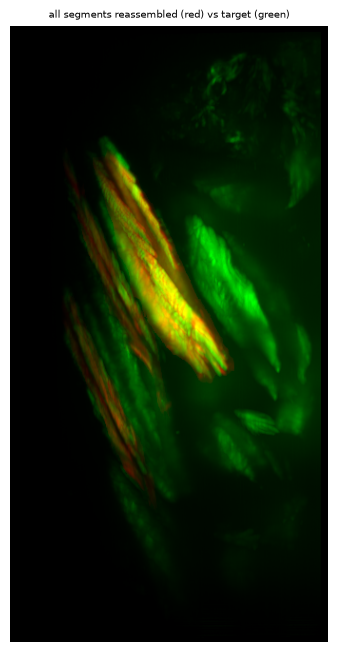

In [15]:
ax_proj = 0
overlay = red_green_overlay(np.max(ref_assembled, axis=ax_proj), np.max(tar, axis=ax_proj), vmin=100)

plt.figure(figsize=(8, 8))
plt.imshow(overlay)
plt.title('all segments reassembled (red) vs target (green)')
plt.axis('off')
plt.show()

In [ ]:
# save the reassembled reference, labels and muscles for viewing in napari

registered_path = tif_folder / f'{tar_name}-registered.tif'
registered_labels_path = tif_folder / f'{tar_name}-registered_labels.tif'
registered_muscles_path = tif_folder / f'{tar_name}-registered_muscles.tif'

tifffile.imwrite(registered_path, ref_assembled)
tifffile.imwrite(registered_labels_path, labels_assembled)
tifffile.imwrite(registered_muscles_path, muscles_assembled)

print(f'Saved registered reference to {registered_path}')
print(f'Saved registered labels to {registered_labels_path}')
print(f'Saved registered muscles to {registered_muscles_path}')

overwriting!
Running affine registration...

	spam.DIC.registerMultiscale(): working on binning:  4


It#:001 |δΦ|=0.94097 error=   5.45 t=[ -0.488  -0.344  -0.726]px r=[  0.261   0.385  -0.135]° stretch=[0.978 0.995 
0.979]

It#:002 |δΦ|=0.48973 error=   4.37 t=[ -0.716  -0.516  -1.101]px r=[  0.322   1.499  -0.082]° stretch=[0.972 0.992 
0.969]

It#:003 |δΦ|=0.22389 error=   4.17 t=[ -0.799  -0.616  -1.269]px r=[  0.207   2.116   0.046]° stretch=[0.975 0.990 
0.968]

It#:004 |δΦ|=0.09588 error=   4.13 t=[ -0.835  -0.661  -1.340]px r=[  0.133   2.348   0.144]° stretch=[0.977 0.989 
0.969]

...

It#:013 |δΦ|=0.00021 error=   5.14 t=[ -3.479  -3.064  -5.732]px r=[ -0.016   2.631   0.240]° stretch=[0.988 0.988 
0.973]

It#:014 |δΦ|=0.00015 error=   5.14 t=[ -3.479  -3.064  -5.732]px r=[ -0.016   2.631   0.240]° stretch=[0.988 0.988 
0.973]

It#:015 |δΦ|=0.00010 error=   5.14 t=[ -3.479  -3.064  -5.732]px r=[ -0.016   2.631   0.240]° stretch=[0.988 0.988 
0.973]

It#:016 |δΦ|=0.00008 error=   5.14 t=[ -3.479  -3.064  -5.732]px r=[ -0.016   2.631   0.240]° stretch=[0.988 0.988 
0.973]


	 → Converged
returnStatus: 2 (2 = converged)
error: 5.141601


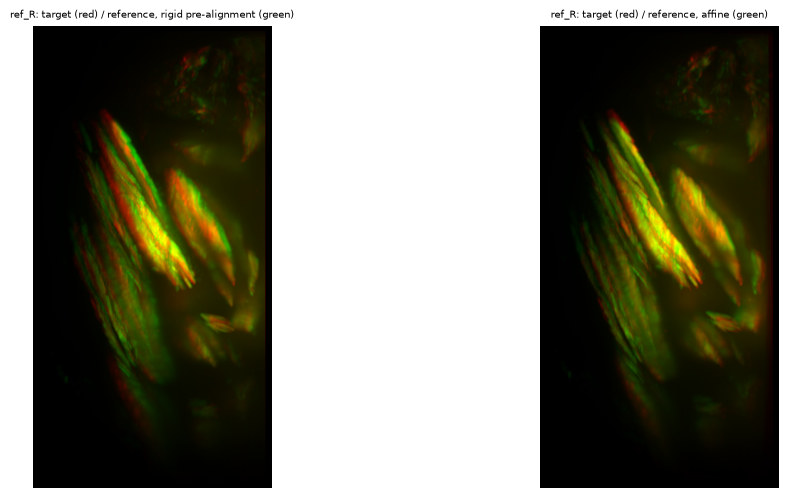

In [18]:
# AFFINE REGISTRATION of the reference to the target, then deform the reference labels and
# muscles with the same transformation


def warp_labels(labels: np.ndarray, phi: np.ndarray) -> np.ndarray:
    """
    Warps a label volume by `phi`, one label ID at a time.

    `spam.DIC.applyPhi` only interpolates linearly, which would blend
    neighbouring label IDs into meaningless fractional values, so each
    ID is warped as its own 0/1 mask. Each voxel then takes the ID
    whose warped mask is highest there, as long as that is above 0.5.

    Parameters
    ----------
    labels : ndarray
        Label volume (0 = background).

    phi : ndarray
        4x4 Phi (see `spam.DIC.applyPhi`), centred at the image centre.

    Returns
    -------
    ndarray
        Warped label volume, same shape/dtype as `labels`.
    """
    warped = np.zeros_like(labels)
    best_weight = np.zeros(labels.shape, dtype='float32')
    for label in np.unique(labels[labels != 0]):
        weight = spam.DIC.applyPhi((labels == label).astype('float32'), Phi=phi)
        take = (weight > 0.5) & (weight > best_weight)
        warped[take] = label
        best_weight[take] = weight[take]
    return warped


# affine registration of the (rigidly pre-aligned) reference to the target
affine_file_name = f'{tar_name}-affine-registration.tsv'
try:
    if overwrite:
        print('overwriting!')
        raise Exception
    phi_affine = spam.helpers.readCorrelationTSV(spam_folder / affine_file_name)['PhiField'][0]
    print('LOADED PRE-EXISTANT AFFINE REGISTRATION')

except Exception:
    print('Running affine registration...')
    reg = spam.DIC.registerMultiscale(
        ref, tar,
        binStart=4, binStop=1,
        PhiInit=None,
        PhiRigid=False,  # affine (rotation, scaling, shear and translation)
        verbose=True,
    )
    print('returnStatus:', reg['returnStatus'], '(2 = converged)')
    print('error:', reg['error'])

    regCentre = (np.array(ref.shape) - 1) / 2.0
    spam.helpers.writeRegistrationTSV(spam_folder / affine_file_name, regCentre, reg)
    phi_affine = reg['Phi']

# deform the reference, its labels and its muscles to match the target
ref_affine = spam.DIC.applyPhi(ref, Phi=phi_affine)
lab_affine = warp_labels(lab1, phi_affine)
muscle_affine = warp_labels(mus1, phi_affine)

# save the deformed volumes for viewing in napari
tifffile.imwrite(tif_folder / f'{tar_name}-affine_registered.tif', ref_affine)
tifffile.imwrite(tif_folder / f'{tar_name}-affine_registered_labels.tif', lab_affine)
tifffile.imwrite(tif_folder / f'{tar_name}-affine_registered_muscles.tif', muscle_affine)

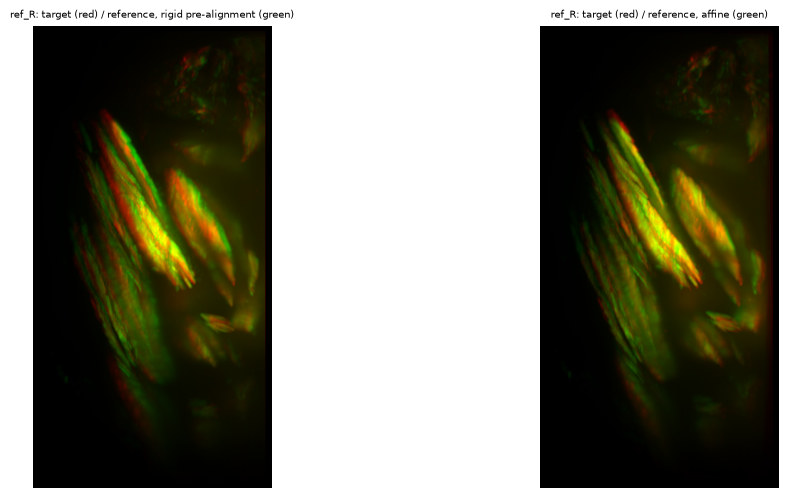

In [19]:
# check: target (red) vs reference before (rigid pre-alignment only) and after the affine
fig, axes = plt.subplots(1, 2, figsize=[12, 6])
for ax, ref_volume, title in ((axes[0], ref, 'rigid pre-alignment'), (axes[1], ref_affine, 'affine')):
    ax.imshow(red_green_overlay(np.max(tar, axis=0), np.max(ref_volume, axis=0), vmin=100))
    ax.set_title(f'{tar_name}: target (red) / reference, {title} (green)')
    ax.axis('off')
plt.show()

In [43]:
stop here

SyntaxError: invalid syntax (4067800170.py, line 1)

In [ ]:
# MANUAL EYE-REGISTRATION FALLBACK (spam-ereg) for labels ddic still can't nail

ereg_folder = spam_folder / 'ereg'
ereg_folder.mkdir(exist_ok=True)


def export_label_for_ereg(label: int, half_size: int = 60) -> None:
    """
    Crops REFERENCE and TARGET around `label`'s centre of mass and saves
    them as TIFFs, ready for manual alignment in `spam-ereg`.

    The crop is centred exactly on `centresOfMass[label]` (zero-padded
    via `spam.helpers.slicePadded` if that runs past the image edge, so
    the crop is always exactly centred there even for edge-adjacent
    labels, e.g. label 7). `spam-ereg`'s saved Phi is anchored at the
    centre of whatever crop it's given, so it lands on the exact same
    anchor point `ddic`/`pixelSearchDiscrete` use for this label - the
    saved Phi can be plugged straight into `PhiField[label]` with no
    further coordinate conversion (see `import_ereg_result`).

    Parameters
    ----------
    label : int
        Label to export a crop for.

    half_size : int
        Half-width of the cubic crop around the centre of mass, in
        voxels (crop is `2 * half_size + 1` per side). Increase this
        if `label`'s own extent doesn't comfortably fit inside the
        default crop.

    Returns
    -------
    None
    """
    centre = np.round(centresOfMass[label]).astype(int)
    startStop = [
        centre[0] - half_size, centre[0] + half_size + 1,
        centre[1] - half_size, centre[1] + half_size + 1,
        centre[2] - half_size, centre[2] + half_size + 1,
    ]
    ref_crop = spam.helpers.slicePadded(ref, startStop)
    tar_crop = spam.helpers.slicePadded(tar, startStop)

    ref_path = ereg_folder / f'label{label}_ref.tif'
    tar_path = ereg_folder / f'label{label}_tar.tif'
    tifffile.imwrite(ref_path, ref_crop)
    tifffile.imwrite(tar_path, tar_crop)

    print(f'Saved crops for label {label} to {ereg_folder}')
    print('In a terminal, run:\n')
    print(f'  spam-ereg {ref_path} {tar_path}\n')
    print('Align by eye, then click "Save TSV" and save it as:')
    print(f'  {ereg_folder / f"label{label}.tsv"}')


def import_ereg_result(label: int, PhiField: np.ndarray) -> np.ndarray:
    """
    Reads back a manually-saved `spam-ereg` result for `label` (see
    `export_label_for_ereg`) and substitutes it into `PhiField[label]`.

    Because the exported crop was centred exactly on
    `centresOfMass[label]`, the Phi `spam-ereg` saved is already
    anchored at the same point `ddic`/`pixelSearchDiscrete` use, so no
    coordinate conversion is needed here.

    Parameters
    ----------
    label : int
        Label whose manual result to import.

    PhiField : ndarray
        Existing per-label PhiField (e.g. `PhiField_ddic` or
        `PhiField_ps`) to update. Not modified in place.

    Returns
    -------
    ndarray
        `PhiField`, with `PhiField[label]` replaced by the manually
        found Phi.
    """
    tsv_path = ereg_folder / f'label{label}.tsv'
    phi_manual = spam.helpers.readCorrelationTSV(tsv_path)['PhiField'][0]

    PhiField_updated = PhiField.copy()
    PhiField_updated[label] = phi_manual
    return PhiField_updated

In [ ]:
# export a problem label's crop for manual alignment - run the printed spam-ereg command in a terminal

label_to_fix = 7
export_label_for_ereg(label_to_fix)

In [ ]:
# after running spam-ereg and saving its TSV: import the manual result and check it visually

PhiField_manual = import_ereg_result(label_to_fix, PhiField_ddic)

overlay = per_label_overlay(label_to_fix, PhiField_manual)

plt.figure(figsize=(5, 5))
plt.imshow(overlay)
plt.title(f'label {label_to_fix}: manual (spam-ereg) alignment')
plt.axis('off')
plt.show()

# once you're happy with it, PhiField_manual[label_to_fix] is ready to use as the final
# Phi for this label (e.g. in place of PhiField_ddic[label_to_fix] downstream)